<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); padding: 30px; border-radius: 8px; margin-bottom: 25px;">
    <h1 style="color: #f8fafc; font-family: 'Segoe UI', sans-serif; font-weight: 700; margin: 0; font-size: 2.2em;">Estratificación en PISA (2012-2022)</h1>
    <p style="color: #94a3b8; font-family: 'Segoe UI', sans-serif; margin: 8px 0 0 0; font-size: 1.1em;">Generación de estratos fijos inter-edición para modelos comparativos</p>
</div>

Una decisión importante en el diseño consiste en delimitar con precisión qué variables definen al **contenedor institucional (el colegio)** y cuáles pertenecen al **agente individual (el estudiante y su familia)** de tal forma que puedan generarse comparativas precisas inter-edición e intra-escolar.



En la definición de los perfiles o estratos escolares se contemplo la evaluación de un conjunto amplio de variables candidatas para caracterizar el contenedor institucional:

* **Estatus socioeconómico agregado (`ESCS_medio_colegio`):** Promedio escolar del índice de estatus económico, social y cultural.Permitiría crear estratos sociales.
* **Titularidad y régimen financiero (`SCHLTYPE` / `PROPFUND`):** Naturaleza jurídica (público, concertado, privado) o porcentaje de financiación pública recibida.
* **Entorno territorial (`SC001Q01TA`):** Tamaño demográfico de la localidad donde se ubica el centro (rural o urbano).
* **Escala física del centro (`SCHSIZE`):** Tamaño total del centro educativo.

Para garantizar la validez metodológica y evitar sesgos en la estimación de los efectos individuales (recursos del hogar y esfuerzo del estudiante), a continuación se realiza un **estudio empírico preliminar que justifica la exclusión del `ESCS_medio_colegio` y la selección exclusiva de variables exógenas y fijas** para la construcción de los perfiles institucionales.

# 1. *Carga de datos y librerías*

In [146]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display

# Configuración global de entorno visual y avisos
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

# Rutas base de los archivos anuales de entrada
RUTA_DATOS_ANUALES = Path("../../data/raw/datos_anuales")
RUTA_ESTUDIANTES_2022 = RUTA_DATOS_ANUALES / "pisa2022_estudiantes.parquet"
RUTA_COLEGIOS_2022 = RUTA_DATOS_ANUALES / "pisa2022_colegios.parquet"

Cargamos los datos necesarios para los estratos dentro de `data/raw/datos_anuales` que contiene los archivos parquet necesarios

In [147]:
# Cargamos únicamente las columnas estrictamente necesarias del nivel estudiante para optimizar RAM

cols_micro_2022 = ["CNT", "CNTSCHID", "CNTSTUID", "ESCS", "HOMEPOS", "W_FSTUWT"] 

df_alumnos_2022 = pd.read_parquet(RUTA_ESTUDIANTES_2022, columns=cols_micro_2022)

print((list(df_alumnos_2022.columns)))

['CNT', 'CNTSCHID', 'CNTSTUID', 'ESCS', 'HOMEPOS', 'W_FSTUWT']


# 2. Estudio del índice socio económico ESCS

El **Índice de Estatus Económico, Social y Cultural (`ESCS`)** es un indicador compuesto estandarizado por la OCDE en PISA para sintetizar el capital socioeconómico y cultural del hogar del estudiante

### Posibles estratos escolares basados en ESCS

Al agregar el valor individual del alumno al nivel de centro mediante el promedio ponderado (`ESCS_medio_colegio`), se podrían categorizar los colegios según el perfil socioeconómico de su alumnado:

1. **Estrato Socioeconómico Bajo:** Colegios en el tercil/cuartil inferior de `ESCS_medio_colegio` (entornos de vulnerabilidad socioeducativa).
2. **Estrato Socioeconómico Medio:** Colegios en los terciles/cuartiles intermedios.
3. **Estrato Socioeconómico Alto:** Colegios en el tercil/cuartil superior de `ESCS_medio_colegio` (entornos de alto capital sociocultural).

Ante esta posibilidad, cabe plantearse dos cuestiones antes de definir los estratos: hasta qué punto este índice refleja realmente al centro educativo y qué grado de correlación presenta con los recursos individuales del alumno (`HOMEPOS`).

## Calculo de la media ponderada `ESCS`

In [148]:
# Calculamos ESCS_medio_colegio ponderado por W_FSTUWT exclusivamente para evidenciar el sesgo

#Mascara para filtrar datos nulos
mask_val = df_alumnos_2022["ESCS"].notna() & df_alumnos_2022["W_FSTUWT"].notna()

#Copia local
df_temp_escs = df_alumnos_2022.loc[mask_val, ["CNT", "CNTSCHID", "ESCS", "W_FSTUWT"]].copy()


<div style=" background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); backdrop-filter: blur(4px); -webkit-backdrop-filter: blur(4px); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; color: inherit; margin: 20px 0; "> 
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">Ponderación muestral del ESCS</strong> 
  El <code>ESCS_medio_colegio</code> se calcula como una media ponderada por el peso final del estudiante (<code>W_FSTUWT</code>): 
  
  <span style="display: inline-flex; align-items: center; font-style: italic; font-family: 'Times New Roman', Times, serif; font-size: 1.1em; margin: 0 4px; vertical-align: middle;">
    <span style="text-decoration: overline; font-style: normal; margin-right: 1px;">x</span><sub>escuela</sub>&nbsp;=&nbsp;&sum;<sub>i</sub>x<sub>i</sub>w<sub>i</sub>&nbsp;/&nbsp;&sum;<sub>i</sub>w<sub>i</sub>
  </span>. 

  El código implementa esta fórmula en dos pasos: primero multiplica cada <code>ESCS</code> por su peso (numerador) y, tras el <code>groupby</code>, divide la suma de productos entre la suma de pesos (denominador). Dado que <code>W_FSTUWT</code> indica cuántos estudiantes de 15 años de la población representa cada alumno encuestado, la ponderación es la práctica estándar recomendada por la OCDE para que el indicador estime la composición de la población del centro y no solo la de la muestra.
  
   En PISA 2022 los pesos apenas varían dentro de un mismo colegio , por lo que la media ponderada y la simple son prácticamente idénticas. Se mantiene la versión ponderada por rigor y coherencia metodológica. 
</div>




In [149]:
#Calculo del numerador
df_temp_escs["_escs_w"] = df_temp_escs["ESCS"] * df_temp_escs["W_FSTUWT"]

#Calculo de los coeficientes palos colegios
escs_meso = (
    df_temp_escs.groupby(["CNT", "CNTSCHID"], as_index=False) 
    .agg(_num=("_escs_w", "sum"), _den=("W_FSTUWT", "sum")) 
)
escs_meso["ESCS_medio_colegio"] = escs_meso["_num"] / escs_meso["_den"] #Calclo de la media ponderada para cada colegio

#Juntamos la media en el dataframe de alumnos 
df_sesgo = (
    df_alumnos_2022[["CNT", "CNTSCHID", "HOMEPOS"]]
    .merge(escs_meso[["CNT", "CNTSCHID", "ESCS_medio_colegio"]], on=["CNT", "CNTSCHID"], how="inner")
    .dropna(subset=["ESCS_medio_colegio", "HOMEPOS"])
)

## Calculo de la correlacion con HOMEPOS ( Variable de recursos )

In [150]:
# Calculamos la correlación de Pearson entre las dos variables
corr_pearson = df_sesgo["ESCS_medio_colegio"].corr(df_sesgo["HOMEPOS"])

print(
    f"Correlación de Pearson (ESCS_medio_colegio y HOMEPOS): r = {corr_pearson:.4f} "
    f"(N = {len(df_sesgo):,} alumnos)"
)

Correlación de Pearson (ESCS_medio_colegio y HOMEPOS): r = 0.5228 (N = 261,003 alumnos)


Una correlacion simple de ambas variables nos da una **correlacion medio-moderada**

## Visualización de ESCS y HOMEPOS

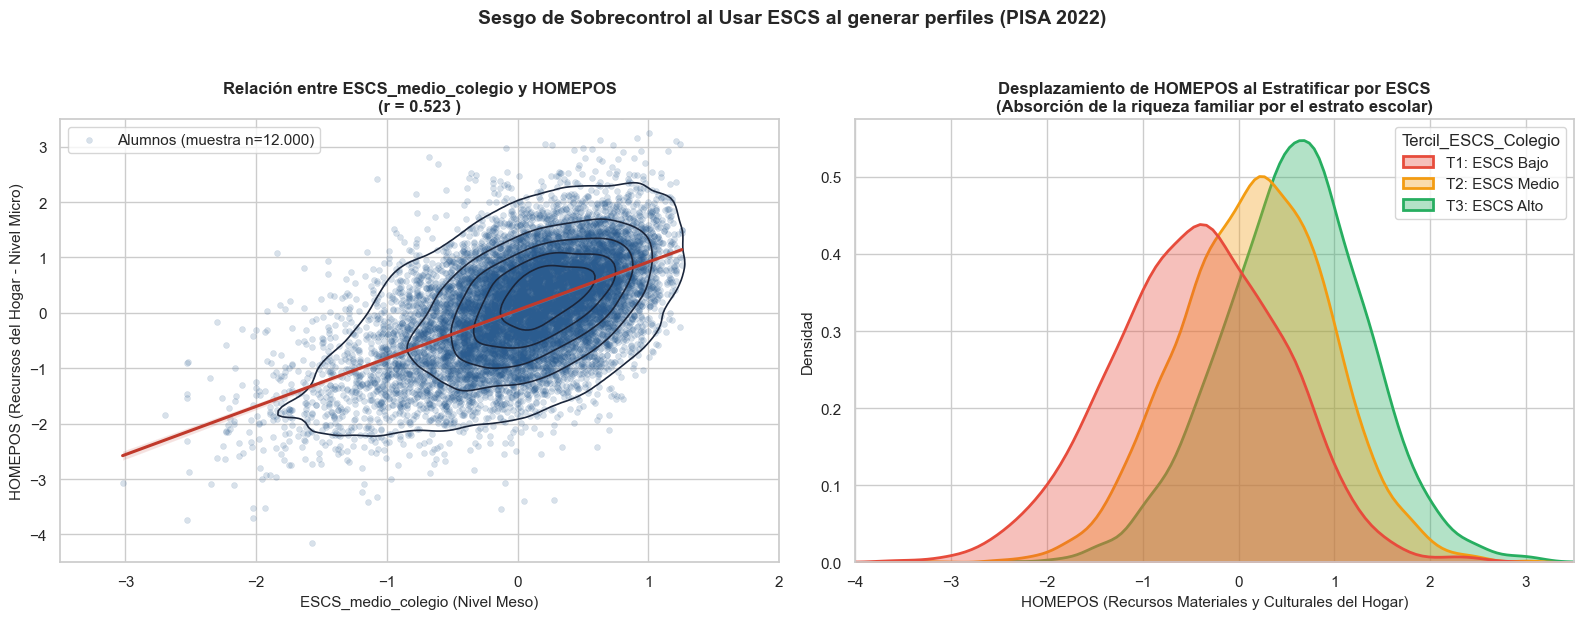

In [151]:

# Muestra aleatoria reproducible para renderizar con fluidez el Scatter + KDE
df_muestra_plot = df_sesgo.sample(n=min(12_000, len(df_sesgo)), random_state=42).copy()

#Dividimos en terciles los diferentes estratos de acuerdo al ESCS
df_muestra_plot["Tercil_ESCS_Colegio"] = pd.qcut(
    df_muestra_plot["ESCS_medio_colegio"],
    q=3,
    labels=["T1: ESCS Bajo", "T2: ESCS Medio", "T3: ESCS Alto"],
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel Izquierdo: Scatter Plot + Contornos KDE + Regresión lineal
sns.scatterplot(
    data=df_muestra_plot,
    x="ESCS_medio_colegio",
    y="HOMEPOS",
    alpha=0.18,
    s=18,
    color="#2b5c8f",
    edgecolor=None,
    ax=axes[0],
    label="Alumnos (muestra n=12.000)",
)
sns.kdeplot(
    data=df_muestra_plot,
    x="ESCS_medio_colegio",
    y="HOMEPOS",
    levels=6,
    color="#1b263b",
    linewidths=1.2,
    ax=axes[0],
)
sns.regplot(
    data=df_muestra_plot,
    x="ESCS_medio_colegio",
    y="HOMEPOS",
    scatter=False,
    color="#c0392b",
    line_kws={"linewidth": 2.2, "label": f"Tendencia lineal (r = {corr_pearson:.2f})"},
    ax=axes[0],
)
axes[0].set_title(
    "Relación entre ESCS_medio_colegio y HOMEPOS\n"
    f"(r = {corr_pearson:.3f} )",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("ESCS_medio_colegio (Nivel Meso)", fontsize=11)
axes[0].set_ylabel("HOMEPOS (Recursos del Hogar - Nivel Micro)", fontsize=11)
axes[0].set_xlim(-3.5, 2.0)
axes[0].set_ylim(-4.5, 3.5)
axes[0].legend(loc="upper left")

# Panel Derecho: KDE de HOMEPOS condicionado al tercil de ESCS_medio_colegio
sns.kdeplot(
    data=df_muestra_plot,
    x="HOMEPOS",
    hue="Tercil_ESCS_Colegio",
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2,
    palette=["#e74c3c", "#f39c12", "#27ae60"],
    ax=axes[1],
)
axes[1].set_title(
    "Desplazamiento de HOMEPOS al Estratificar por ESCS\n"
    "(Absorción de la riqueza familiar por el estrato escolar)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("HOMEPOS (Recursos Materiales y Culturales del Hogar)", fontsize=11)
axes[1].set_ylabel("Densidad", fontsize=11)
axes[1].set_xlim(-4.0, 3.5)

fig.suptitle(
    "Sesgo de Sobrecontrol al Usar ESCS al generar perfiles (PISA 2022)",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)
fig.tight_layout()
plt.show()




## ¿ Por qué descartamos ESCS ?


1. **Naturaleza de origen familiar, no institucional:** El índice `ESCS` (*Economic, Social and Cultural Status*) de PISA es un constructo compuesto por el nivel educativo parental (`PARED`), el estatus ocupacional más alto de los padres (`HISEI`) y las posesiones materiales y culturales del hogar (`HOMEPOS`). Por tanto, el `ESCS` no mide ningún atributo físico, administrativo ni organizativo del edificio escolar, sino el capital socioeconómico agregado de las familias que acuden a él.

2. **Absorción artificial de la varianza de la riqueza (`HOMEPOS`):** Dado que `HOMEPOS` es uno de los tres pilares constitutivos del `ESCS`, agrupar los colegios según su `ESCS_medio_colegio` equivale a estratificar indirectamente por el nivel de recursos materiales del hogar. Si el estrato meso ya captura la riqueza familiar, al estimar en el Nivel Micro el efecto de los **recursos familiares (`HOMEPOS`) frente al esfuerzo individual**, gran parte de la varianza de `HOMEPOS` habrá sido absorbida por el estrato, sesgando a la baja su verdadero impacto.

3. **Aislamiento limpio del contenedor físico:** Al sustituir el `ESCS_medio_colegio` por la **dimensión física de la matrícula (`SCHSIZE`)**, junto con la **titularidad/financiación (`SCHLTYPE`/`PROPFUND`)** y el **entorno geográfico (`SC001Q01TA`)**, construimos perfiles **100 % institucionales**. De este modo, el estrato controla estrictamente por la escala, administración y localización del centro, dejando la riqueza familiar (`HOMEPOS`) y el esfuerzo del alumno libres de colinealidad inducida.




# 3. Selección de Variables Institucionales y Morfológicas

Descartado el uso del estatus socioeconómico en el apartado anterior, pasamos a construir los estratos exclusivamente a partir de **variables institucionales y composicion del centro educativo**:

1. **Titularidad / Régimen de Financiación (`SCHLTYPE` / `PROPFUND`):** Distingue la naturaleza jurídica y financiera de la escuela. En los cuestionarios de dirección de PISA existen dos vías para capturar este eje:
   * La variable categórica derivada **`SCHLTYPE`** (que clasifica los centros en *Públicos*, *Privados Concertados/Dependientes del Gobierno* y *Privados Independientes*).
   * La variable continua **`PROPFUND`** (proveniente de las variantes de la pregunta `SC016Q01`: `SC016Q01JA` / `SC016Q01TA`, que recoge el porcentaje exacto de financiación procedente del gobierno).

2. **Entorno Físico (`SC001Q01TA`):** Captura el tamaño demográfico del municipio en el que se ubica físicamente la escuela (desde aldeas rurales hasta grandes áreas metropolitanas).

3. **Dimensión del Centro (`SCHSIZE`):** Mide el tamaño total del centro educativo, reflejando la escala física y organizativa de las instalaciones.


## ¿SCHLTYPE o PROPFUND? El problema de los datos faltantes (evaluación en PISA 2022) 

Por motivos de confidencialidad estadística o falta de respuesta en los cuestionarios de dirección, la disponibilidad de `SCHLTYPE` y `PROPFUND` varía entre países y entre ciclos de PISA. Para maximizar la representatividad muestral sin recurrir a imputaciones artificiales entre sistemas educativos distintos, aplicamos una regla objetiva de selección por edición:

1. Calculamos para **PISA 2022** el porcentaje de valores nulos (`NaN`) por país (`CNT`) tanto en `SCHLTYPE` como en `PROPFUND`.

2. Establecemos un umbral de viabilidad nacional del **50 % de nulos**: cualquier país que supere el 50 % de datos faltantes en la variable evaluada se excluye en esa dimensión. Se selecciona automáticamente la variable que permita tener mayor cobertura en la edición analizada. Esto es, la variable que retiene más países por debajo del umbral (y, a igual número de países retenidos, la que conserva mayor número total de colegios válidos).


<div style="
  background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%);
  backdrop-filter: blur(4px);
  border-left: 5px solid rgba(128, 128, 128, 0.6);
  padding: 16px;
  border-radius: 8px;
  margin: 20px 0;
">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    💡 Nota Multiedición
  </strong>
 El cálculo que se muestra a continuación corresponde específicamente a <b>PISA 2022</b>. Al aplicar este pipeline a otras ediciones (2012, 2015 o 2018), la distribución de valores nulos puede variar y resultar seleccionada <code>PROPFUND</code> en lugar de <code>SCHLTYPE</code>.
</div>

In [152]:
# Inspección del esquema para detectar la variante de financiación disponible en 2022
esquema_col_2022 = set(pq.read_schema(RUTA_COLEGIOS_2022).names)
col_propfund_raw = "SC016Q01JA" if "SC016Q01JA" in esquema_col_2022 else "SC016Q01TA"

# Carga exclusiva de las variables institucionales de interés y estandarización de nombre
cols_institucionales = ["CNT", "CNTSCHID", "SCHLTYPE", col_propfund_raw, "SC001Q01TA", "SCHSIZE"]
df_colegios_raw = pd.read_parquet(RUTA_COLEGIOS_2022, columns=cols_institucionales).rename(
    columns={col_propfund_raw: "PROPFUND"}
)

## Cálculo de valores nulos (PISA 2022)

In [153]:
# Parámetros para el filtrado de cobertura nacional por variable de titularidad
UMBRAL_NULOS_PAIS = 50.0
variables_titularidad = ["SCHLTYPE", "PROPFUND"]
resumen = []

# Agregación a nivel de colegio (['CNT', 'CNTSCHID']) mediante .first() para PISA 2022
df_colegios_2022 = (
    df_colegios_raw.groupby(["CNT", "CNTSCHID"], as_index=False)
    .agg(
        SCHLTYPE=("SCHLTYPE", "first"),
        PROPFUND=("PROPFUND", "first"),
        SC001Q01TA=("SC001Q01TA", "first"),
        SCHSIZE=("SCHSIZE", "first"),
    )
)

# Cálculo del % de NaNs por país en PISA 2022 y ordenación descendente según media de nulos
nulos_pais = (
    df_colegios_2022.groupby("CNT")[["SCHLTYPE", "PROPFUND"]]
    .apply(lambda g: g.isna().mean() * 100)
    .reset_index()
)
nulos_pais["_orden"] = nulos_pais[["SCHLTYPE", "PROPFUND"]].mean(axis=1)
nulos_pais = nulos_pais.sort_values("_orden", ascending=False).drop(columns="_orden")

# Evaluación de países retenidos y colegios válidos bajo el umbral del 50 %
for var in variables_titularidad:
    paises_descartados = sorted(nulos_pais.loc[nulos_pais[var] > UMBRAL_NULOS_PAIS, "CNT"].tolist())
    colegios_validos = df_colegios_2022.loc[~df_colegios_2022["CNT"].isin(paises_descartados), var].notna().sum()
    
    resumen.append({
        "Variable": var,
        "Países Retenidos": len(nulos_pais) - len(paises_descartados),
        "Países Descartados (N)": len(paises_descartados),
        "Colegios Válidos": int(colegios_validos),
        "Lista Países Descartados": paises_descartados
    })

df_comparativa = pd.DataFrame(resumen)

# Mostrar la tabla de cobertura de PISA 2022
display(df_comparativa.drop(columns=["Lista Países Descartados"]))

# Selección automática de la variable con mayor cobertura en la edición evaluada
idx_seleccionada = df_comparativa.sort_values(by=["Países Retenidos", "Colegios Válidos"], ascending=False).index[0]
variable_seleccionada = df_comparativa.loc[idx_seleccionada, "Variable"]
paises_excluidos = df_comparativa.loc[idx_seleccionada, "Lista Países Descartados"]

print(f"\n-> Variable seleccionada para PISA 2022: {variable_seleccionada}")
print(f"-> Países excluidos en PISA 2022: {paises_excluidos}\n")

# Filtrado de países excluidos y eliminación de registros incompletos en las tres dimensiones
cols_limpieza = [variable_seleccionada, "SC001Q01TA", "SCHSIZE"]

df_colegios_2022 = (
    df_colegios_2022.loc[~df_colegios_2022["CNT"].isin(paises_excluidos)]
    .dropna(subset=cols_limpieza)
    .reset_index(drop=True)
)

print(f"Dataset PISA 2022 listo: {len(df_colegios_2022):,} colegios completos en {df_colegios_2022['CNT'].nunique()} países.")

,Variable,Países Retenidos,Países Descartados (N),Colegios Válidos
0,SCHLTYPE,28,5,8726
1,PROPFUND,28,5,8256



-> Variable seleccionada para PISA 2022: SCHLTYPE
-> Países excluidos en PISA 2022: ['AUT', 'BEL', 'IRL', 'ISR', 'NOR']

Dataset PISA 2022 listo: 6,987 colegios completos en 25 países.


En la edición de **PISA 2022** seleccionamos `SCHLTYPE`: aunque ambas variables retienen exactamente el mismo número de países por debajo del umbral del 50 % de nulos (28 países retenidos y 5 excluidos), `SCHLTYPE` conserva un mayor número de colegios válidos en la muestra (`8.726` frente a `8.256`). En otras ediciones de PISA la cobertura por país puede variar, por lo que esta misma lógica seleccionará `PROPFUND` si en ese año presenta menor pérdida muestral.

## Visualización de valores nulos y umbral del 50 % (PISA 2022)

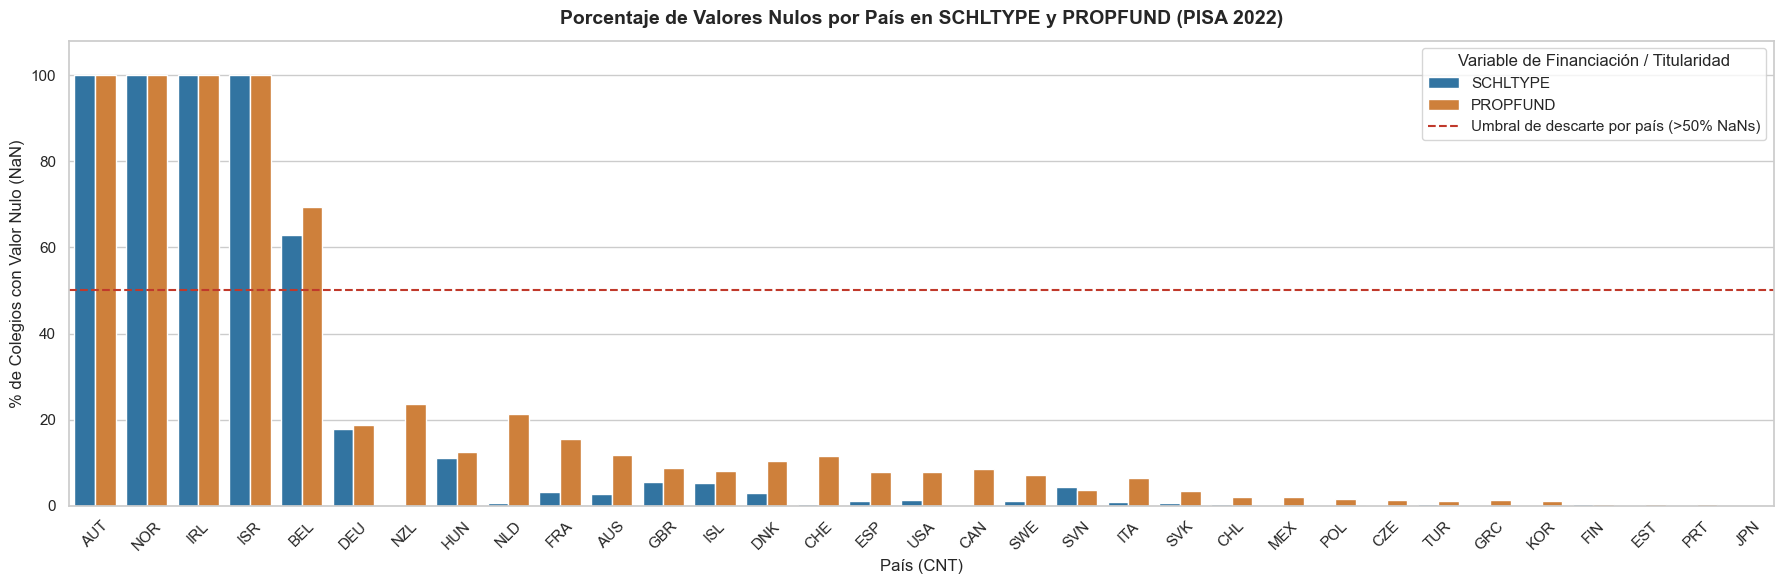

In [154]:
# Transformación a formato largo para graficar ambas variables por país
df_nulos_long = nulos_pais.melt(
    id_vars="CNT",
    value_vars=["SCHLTYPE", "PROPFUND"],
    var_name="Variable",
    value_name="Pct_Nulos",
)

# Gráfico de barras agrupadas de % de valores nulos por país (PISA 2022)
fig, ax = plt.subplots(figsize=(18, 6))
sns.barplot(
    data=df_nulos_long,
    x="CNT",
    y="Pct_Nulos",
    hue="Variable",
    palette={"SCHLTYPE": "#1f77b4", "PROPFUND": "#e67e22"},
    ax=ax,
)
ax.axhline(
    50.0,
    color="#c0392b",
    linestyle="--",
    linewidth=1.5,
    label="Umbral de descarte por país (>50% NaNs)",
)
ax.set_title(
    "Porcentaje de Valores Nulos por País en SCHLTYPE y PROPFUND (PISA 2022)",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("País (CNT)", fontsize=12)
ax.set_ylabel("% de Colegios con Valor Nulo (NaN)", fontsize=12)
ax.set_ylim(0, 108)
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Variable de Financiación / Titularidad", loc="upper right")
fig.tight_layout()
plt.show()

En **PISA 2022** se observa un mayor porcentaje de valores nulos para `PROPFUND` en varios países, aunque ambas variables retienen exactamente la misma cantidad de países por debajo del umbral del 50 % (28 países). En otras ediciones de PISA el patrón de datos faltantes puede ser diferente y resultar seleccionada `PROPFUND` cuando disponga de mayor cobertura.

# 4. Creación de Estratos Fijos

Con el directorio de escuelas depurado y tomando la edición **PISA 2022** como referencia principal, construimos los **estratos fijos** discretizando las tres dimensiones físicas y administrativas mediante reglas estáticas. Al prescindir del nivel socioeconómico, garantizamos que los estratos representen exclusivamente **tipos de infraestructura y gestión escolar**:

1. **Financiación / Titularidad (`SCHLTYPE` / `PROPFUND`):**
   * Empleando la variable institucional seleccionada en 2022 (`SCHLTYPE`, codificación oficial OCDE PISA: `3 = Público`, `2 = Privado dependiente del gobierno / Concertado`, `1 = Privado independiente`), generamos los códigos **`PUB`** (*Público*), **`CON`** (*Concertado*) y **`PRI`** (*Privado*). Si en alguna edición resultara seleccionada `PROPFUND`, se aplica la regla equivalente ($\ge 90\% \rightarrow$ `PUB`, $50\text{–}89,9\% \rightarrow$ `CON`, $<50\% \rightarrow$ `PRI`).
2. **Entorno Físico (`SC001Q01TA`):**
   * Agrupamos la escala demográfica en dos contextos territoriales: **`RUR`** (*Rural*, para aldeas $<3.000$ hab. y pueblos pequeños de $3.000$ a $15.000$ hab., códigos `1` y `2`) y **`URB`** (*Urbano*, para ciudades desde $15.000$ hab. hasta grandes áreas metropolitanas, códigos `3`, `4`, `5` y `6`).
3. **Dimensión del Centro (`SCHSIZE`):**
   * Discretizamos el tamaño del centro educativo de 2022 en **3 terciles estáticos** mediante `pd.qcut`: **`PEQ`** (*Escuela Pequeña*), **`MED`** (*Instituto Mediano*) y **`MACRO`** (*Macro-Instituto*). Los umbrales obtenidos en 2022 se fijan como referencia para clasificar de manera homogénea las ediciones anteriores.

Finalmente, generamos dos columnas paralelas para cada colegio:
* **`PERFIL_CODE`:** Identificador corto para regresiones, agrupaciones y ejes gráficos (ej. `PUB_URB_MACRO`).
* **`PERFIL_DESC`:** Descripción semántica legible para tablas e interpretación analítica (ej. `Público | Urbano | Macro-Instituto`).

In [155]:
# Diccionarios de mapeo para codificación y descripción de la titularidad (SCHLTYPE)
MAPEO_SCHLTYPE_CODE = {3.0: "PUB", 2.0: "CON", 1.0: "PRI"}

MAPEO_FIN_DESC = {
    "PUB": "Público",
    "CON": "Concertado",
    "PRI": "Privado",
}

In [156]:
# Mapeo de código y descripción de titularidad para los colegios de 2022
df_colegios_2022["FIN_CODE"] = df_colegios_2022["SCHLTYPE"].map(MAPEO_SCHLTYPE_CODE)
df_colegios_2022["FIN_DESC"] = df_colegios_2022["FIN_CODE"].map(MAPEO_FIN_DESC)

# Diccionarios de mapeo para el entorno físico (SC001Q01TA: 1, 2 -> RUR; 3, 4, 5, 6 -> URB)
MAPEO_UBIC_CODE = {1.0: "RUR", 2.0: "RUR", 3.0: "URB", 4.0: "URB", 5.0: "URB", 6.0: "URB"}
MAPEO_UBIC_DESC = {"RUR": "Rural", "URB": "Urbano"}

df_colegios_2022["UBIC_CODE"] = df_colegios_2022["SC001Q01TA"].map(MAPEO_UBIC_CODE)
df_colegios_2022["UBIC_DESC"] = df_colegios_2022["UBIC_CODE"].map(MAPEO_UBIC_DESC)

# Constantes de etiquetas para la escala física del centro (SCHSIZE)
CODIGOS_TAM = ["PEQ", "MED", "MACRO"]
MAPEO_TAM_DESC = {
    "PEQ": "Escuela Pequeña",
    "MED": "Instituto Mediano",
    "MACRO": "Macro-Instituto",
}

# Generación de los terciles de tamaño en 2022 (sus cortes servirán de referencia fija inter-edición)
df_colegios_2022["TAM_CODE"], cortes_schsize = pd.qcut(
    df_colegios_2022["SCHSIZE"],
    q=3,
    labels=CODIGOS_TAM,
    retbins=True,
)
df_colegios_2022["TAM_CODE"] = df_colegios_2022["TAM_CODE"].astype(str)
df_colegios_2022["TAM_DESC"] = df_colegios_2022["TAM_CODE"].map(MAPEO_TAM_DESC)

print(
    f"Cortes de terciles de SCHSIZE (tamaño del centro educativo):\n"
    f"  - PEQ   (Escuela Pequeña):   [{cortes_schsize[0]:.0f} - {cortes_schsize[1]:.0f}]\n"
    f"  - MED   (Instituto Mediano): ({cortes_schsize[1]:.0f} - {cortes_schsize[2]:.0f}]\n"
    f"  - MACRO (Macro-Instituto):   ({cortes_schsize[2]:.0f} - {cortes_schsize[3]:.0f}]"
)

# Concatenación de las tres dimensiones para formar el código y la descripción de cada estrato fijo
df_colegios_2022["PERFIL_CODE"] = (
    df_colegios_2022["FIN_CODE"]
    + "_"
    + df_colegios_2022["UBIC_CODE"]
    + "_"
    + df_colegios_2022["TAM_CODE"]
)

df_colegios_2022["PERFIL_DESC"] = (
    df_colegios_2022["FIN_DESC"]
    + " | "
    + df_colegios_2022["UBIC_DESC"]
    + " | "
    + df_colegios_2022["TAM_DESC"]
)

# Cálculo de la tabla resumen a nivel de colegio para su posterior unión con el nivel de estudiante
mapa_code_desc = (
    df_colegios_2022[["PERFIL_CODE", "PERFIL_DESC"]]
    .drop_duplicates()
    .set_index("PERFIL_CODE")["PERFIL_DESC"]
)
frecuencias_institucionales = (
    df_colegios_2022["PERFIL_CODE"]
    .value_counts()
    .rename_axis("PERFIL_CODE")
    .to_frame(name="N_COLEGIOS")
)
frecuencias_institucionales["PERFIL_DESC"] = frecuencias_institucionales.index.map(mapa_code_desc)
frecuencias_institucionales["%_COLEGIOS"] = (
    100 * frecuencias_institucionales["N_COLEGIOS"] / len(df_colegios_2022)
).round(2)
frecuencias_institucionales = frecuencias_institucionales[["PERFIL_DESC", "N_COLEGIOS", "%_COLEGIOS"]]

Cortes de terciles de SCHSIZE (tamaño del centro educativo):
  - PEQ   (Escuela Pequeña):   [9 - 415]
  - MED   (Instituto Mediano): (415 - 819]
  - MACRO (Macro-Instituto):   (819 - 6425]


## Generación de estratos fijos para las ediciones 2018, 2015 y 2012

Aplicamos de forma iterativa la misma lógica de estratificación sobre las ediciones históricas (**2018**, **2015** y **2012**), manteniendo fijos los puntos de corte de `SCHSIZE` obtenidos en 2022 (`<= 415` para `PEQ`, `416 - 819` para `MED` y `> 819` para `MACRO`) y armonizando los nombres de las columnas del cuestionario de centro en 2012 (`SC02Q01` para financiación pública y `SC03Q01` para ubicación).

In [158]:
# Intervalos de tamaño fijos basados en los terciles de 2022 y contenedor de resultados por edición
limites_fijos_schsize = [-np.inf, cortes_schsize[1], cortes_schsize[2], np.inf]
estratos_colegios_por_edicion = {2022: df_colegios_2022}
resumen_ediciones = [
    {
        "Edición": 2022,
        "Variable Titularidad": variable_seleccionada,
        "Países Retenidos": int(df_colegios_2022["CNT"].nunique()),
        "Colegios Clasificados": int(len(df_colegios_2022)),
        "Estratos Fijos Activos": int(df_colegios_2022["PERFIL_CODE"].nunique()),
    }
]

# Función auxiliar para replicar la limpieza, selección de variable y asignación de estratos en cada edición
def generar_estratos_fijos_edicion(edicion: int, limites_tam: list[float]) -> tuple[pd.DataFrame, dict]:
    ruta_col = RUTA_DATOS_ANUALES / f"pisa{edicion}_colegios.parquet"
    esquema = set(pq.read_schema(ruta_col).names)

    # Armonización de nombres de columnas según el cuestionario de cada edición
    col_prop = (
        "SC016Q01JA"
        if "SC016Q01JA" in esquema
        else ("SC016Q01TA" if "SC016Q01TA" in esquema else "SC02Q01")
    )
    col_ubic = "SC001Q01TA" if "SC001Q01TA" in esquema else "SC03Q01"

    # Lectura y colapso a nivel de centro único
    df_col = (
        pd.read_parquet(
            ruta_col, columns=["CNT", "CNTSCHID", "SCHLTYPE", col_prop, col_ubic, "SCHSIZE"]
        )
        .rename(columns={col_prop: "PROPFUND", col_ubic: "SC001Q01TA"})
        .groupby(["CNT", "CNTSCHID"], as_index=False)
        .first()
    )

    # Selección entre SCHLTYPE y PROPFUND según el umbral del 50 % de nulos por país
    nulos = (
        df_col.groupby("CNT")[["SCHLTYPE", "PROPFUND"]]
        .apply(lambda g: g.isna().mean() * 100)
        .reset_index()
    )
    candidatas = []
    for var in ["SCHLTYPE", "PROPFUND"]:
        desc = sorted(nulos.loc[nulos[var] > UMBRAL_NULOS_PAIS, "CNT"].tolist())
        val = int(df_col.loc[~df_col["CNT"].isin(desc), var].notna().sum())
        candidatas.append((var, len(nulos) - len(desc), val, desc))
    candidatas.sort(key=lambda x: (x[1], x[2]), reverse=True)
    var_sel, _, _, paises_excl = candidatas[0]

    # Filtrado de países descartados y registros con valores faltantes
    df_col = (
        df_col.loc[~df_col["CNT"].isin(paises_excl)]
        .dropna(subset=[var_sel, "SC001Q01TA", "SCHSIZE"])
        .reset_index(drop=True)
    )

    # Asignación de códigos y descripciones para las tres dimensiones institucionales
    if var_sel == "SCHLTYPE":
        df_col["FIN_CODE"] = df_col["SCHLTYPE"].map(MAPEO_SCHLTYPE_CODE)
    else:
        df_col["FIN_CODE"] = np.select(
            [df_col["PROPFUND"] >= 90.0, df_col["PROPFUND"] >= 50.0],
            ["PUB", "CON"],
            default="PRI",
        )
    df_col["FIN_DESC"] = df_col["FIN_CODE"].map(MAPEO_FIN_DESC)
    df_col["UBIC_CODE"] = df_col["SC001Q01TA"].map(MAPEO_UBIC_CODE)
    df_col["UBIC_DESC"] = df_col["UBIC_CODE"].map(MAPEO_UBIC_DESC)
    df_col["TAM_CODE"] = pd.cut(
        df_col["SCHSIZE"], bins=limites_tam, labels=CODIGOS_TAM
    ).astype(str)
    df_col["TAM_DESC"] = df_col["TAM_CODE"].map(MAPEO_TAM_DESC)

    df_col["PERFIL_CODE"] = (
        df_col["FIN_CODE"] + "_" + df_col["UBIC_CODE"] + "_" + df_col["TAM_CODE"]
    )
    df_col["PERFIL_DESC"] = (
        df_col["FIN_DESC"] + " | " + df_col["UBIC_DESC"] + " | " + df_col["TAM_DESC"]
    )

    info = {
        "Edición": edicion,
        "Variable Titularidad": var_sel,
        "Países Retenidos": int(df_col["CNT"].nunique()),
        "Colegios Clasificados": int(len(df_col)),
        "Estratos Fijos Activos": int(df_col["PERFIL_CODE"].nunique()),
    }
    return df_col, info

# Ejecución iterativa para las ediciones históricas
for edicion in [2018, 2015, 2012]:
    df_ed, info_ed = generar_estratos_fijos_edicion(edicion, limites_fijos_schsize)
    estratos_colegios_por_edicion[edicion] = df_ed
    resumen_ediciones.append(info_ed)

df_resumen_ediciones = pd.DataFrame(resumen_ediciones)
display(df_resumen_ediciones)

,Edición,Variable Titularidad,Países Retenidos,Colegios Clasificados,Estratos Fijos Activos
0,2022,SCHLTYPE,25,6987,18
1,2018,SCHLTYPE,26,7346,18
2,2015,SCHLTYPE,28,6841,18
3,2012,SCHLTYPE,32,10675,18


# 5. Fusión estrato-alumno

El paso final consiste en transferir la etiqueta de los estratos fijos del colegio (`PERFIL_CODE` y `PERFIL_DESC`) de vuelta al **nivel del estudiante** mediante una fusión mediante la clave `['CNT', 'CNTSCHID']`.

Con esta arquitectura alcanzamos el objetivo central del notebook:

* **Estratos institucionales fijos:** Cada alumno queda ubicado dentro de una «foto fija» de su escuela definida exclusivamente por su régimen de financiación (`PUB`/`CON`/`PRI`), su entorno demográfico (`RUR`/`URB`) y su escala física (`PEQ`/`MED`/`MACRO`).

* **Variables individuales libres de colinealidad en el modelo final:** Al no haber utilizado `ESCS` ni `HOMEPOS` en la construcción del estrato fijo escolar, tanto los **recursos familiares del estudiante (`HOMEPOS`)** como sus **indicadores de esfuerzo y perseverancia** conservan intacta su varianza natural dentro de cada tipo de centro, permitiendo estimar sin sesgo,debido a los estratos, su contribución relativa al rendimiento académico.

In [159]:
# Columnas institucionales del colegio que se transfieren al nivel del estudiante
cols_meso_merge = [
    "CNT",
    "CNTSCHID",
    "SCHLTYPE",
    "SC001Q01TA",
    "SCHSIZE",
    "TAM_CODE",
    "PERFIL_CODE",
    "PERFIL_DESC",
]

# Fusión del directorio de colegios depurado con la tabla de alumnos mediante ['CNT', 'CNTSCHID']
df_estudiantes_final = df_alumnos_2022.merge(
    df_colegios_2022[cols_meso_merge],
    on=["CNT", "CNTSCHID"],
    how="inner",
    validate="many_to_one",
)

print(
    f"Fusión estrato-alumno completada con éxito:\n"
    f"  - Alumnos con estrato fijo asignado: {len(df_estudiantes_final):,} "
    f"(de {len(df_alumnos_2022):,} totales en 2022)\n"
    f"  - Colegios representados:            {df_estudiantes_final['CNTSCHID'].nunique():,}\n"
    f"  - Países en los estratos fijos:      {df_estudiantes_final['CNT'].nunique()}\n"
)

# Selección de columnas para verificar visualmente la unión Alumno + Estrato Fijo + Recursos
columnas_comprobacion = [
    "CNT",
    "CNTSCHID",
    "CNTSTUID",
    "PERFIL_CODE",
    "PERFIL_DESC",
    "HOMEPOS",
    "W_FSTUWT",
]

print("Muestra de la fusión estrato-alumno (Alumno + Estrato Fijo + Recursos ):")
display(
    df_estudiantes_final.dropna(subset=["HOMEPOS"])[columnas_comprobacion].head(10)
)

# Conteo de alumnos por estrato y unión con el resumen de colegios para obtener la vista completa de 2022
frecuencias_alumnos_inst = (
    df_estudiantes_final["PERFIL_CODE"]
    .value_counts()
    .rename_axis("PERFIL_CODE")
    .to_frame(name="N_ALUMNOS")
)
frecuencias_alumnos_inst["%_ALUMNOS"] = (
    100 * frecuencias_alumnos_inst["N_ALUMNOS"] / len(df_estudiantes_final)
).round(2)

frecuencias_alumnos_inst = frecuencias_institucionales[
    ["PERFIL_DESC", "N_COLEGIOS", "%_COLEGIOS"]
].join(frecuencias_alumnos_inst[["N_ALUMNOS", "%_ALUMNOS"]]).sort_values(
    by="N_ALUMNOS", ascending=False
)

print("\nDistribución conjunta de colegios y estudiantes por estrato fijo (PISA 2022):")
display(frecuencias_alumnos_inst)

Fusión estrato-alumno completada con éxito:
  - Alumnos con estrato fijo asignado: 186,094 (de 268,610 totales en 2022)
  - Colegios representados:            6,987
  - Países en los estratos fijos:      25

Muestra de la fusión estrato-alumno (Alumno + Estrato Fijo + Recursos ):


,CNT,CNTSCHID,CNTSTUID,PERFIL_CODE,PERFIL_DESC,HOMEPOS,W_FSTUWT
0,AUS,3600477,3600001,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,2.6992,21.48539
1,AUS,3600016,3600002,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,1.4398,26.35004
2,AUS,3600669,3600004,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,0.9612,34.42706
3,AUS,3600495,3600006,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,-0.9616,30.61080
4,AUS,3600325,3600008,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,-1.4897,8.85803
5,AUS,3600733,3600009,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,0.2102,22.70024
6,AUS,3600266,3600010,CON_URB_PEQ,Concertado | Urbano | Escuela Pequeña,0.7169,17.29327
7,AUS,3600671,3600012,CON_URB_MED,Concertado | Urbano | Instituto Mediano,0.5447,3.91793
8,AUS,3600701,3600015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,-0.5671,12.26490
9,AUS,3600334,3600016,CON_URB_PEQ,Concertado | Urbano | Escuela Pequeña,0.2692,5.27367



Distribución conjunta de colegios y estudiantes por estrato fijo (PISA 2022):


,PERFIL_DESC,N_COLEGIOS,%_COLEGIOS,N_ALUMNOS,%_ALUMNOS
PERFIL_CODE,,,,,
PUB_URB_MACRO,Público | Urbano | Macro-Instituto,1465,20.97,43823,23.55
PUB_URB_MED,Público | Urbano | Instituto Mediano,1405,20.11,42643,22.91
PUB_URB_PEQ,Público | Urbano | Escuela Pequeña,767,10.98,19348,10.40
PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,1051,15.04,18971,10.19
PUB_RUR_MED,Público | Rural | Instituto Mediano,517,7.40,13951,7.50
CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,379,5.42,11184,6.01
CON_URB_MED,Concertado | Urbano | Instituto Mediano,257,3.68,8080,4.34
PUB_RUR_MACRO,Público | Rural | Macro-Instituto,241,3.45,7051,3.79
PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,189,2.71,5426,2.92


# 6. Visualizaciones

## Visualización de la Distribución del tamaño de los colegios por Titularidad y Ubicación

In [160]:
# Filtrado exclusivo para España conservando un registro único por centro educativo (CNTSCHID)
df_esp = (
    df_estudiantes_final[df_estudiantes_final["CNT"] == "ESP"]
    .drop_duplicates(subset=["CNT", "CNTSCHID"])
    .copy()
)

# Extracción del eje Titularidad | Ubicación (ej. "Público | Urbano") para agrupar los tres tamaños en cada fila
df_esp["GRUPO_INST"] = df_esp["PERFIL_DESC"].str.rsplit(" | ", n=1).str[0]

# Ordenación categórica de la escala del centro a partir de TAM_CODE generado en la estratificación
df_esp["Tamanio_Categoria"] = pd.Categorical(
    df_esp["TAM_CODE"], categories=CODIGOS_TAM, ordered=True
)

# Cálculo del total de colegios, peso porcentual y mediana real de SCHSIZE por grupo institucional
stats = df_esp.groupby("GRUPO_INST").size().sort_values(ascending=False).to_frame(name="Total")
stats["Porcentaje"] = (stats["Total"] / len(df_esp) * 100).round(1)
orden_grupos = stats.index.tolist()
medianas = df_esp.groupby("GRUPO_INST")["SCHSIZE"].median().reindex(orden_grupos)

# Separación del outlier extremo (SCHSIZE > 3000) para evitar comprimir la escala horizontal del gráfico
UMBRAL_OUTLIER_VISUAL = 3000
df_outliers = df_esp[df_esp["SCHSIZE"] > UMBRAL_OUTLIER_VISUAL]
df_plot = df_esp[df_esp["SCHSIZE"] <= UMBRAL_OUTLIER_VISUAL].copy()

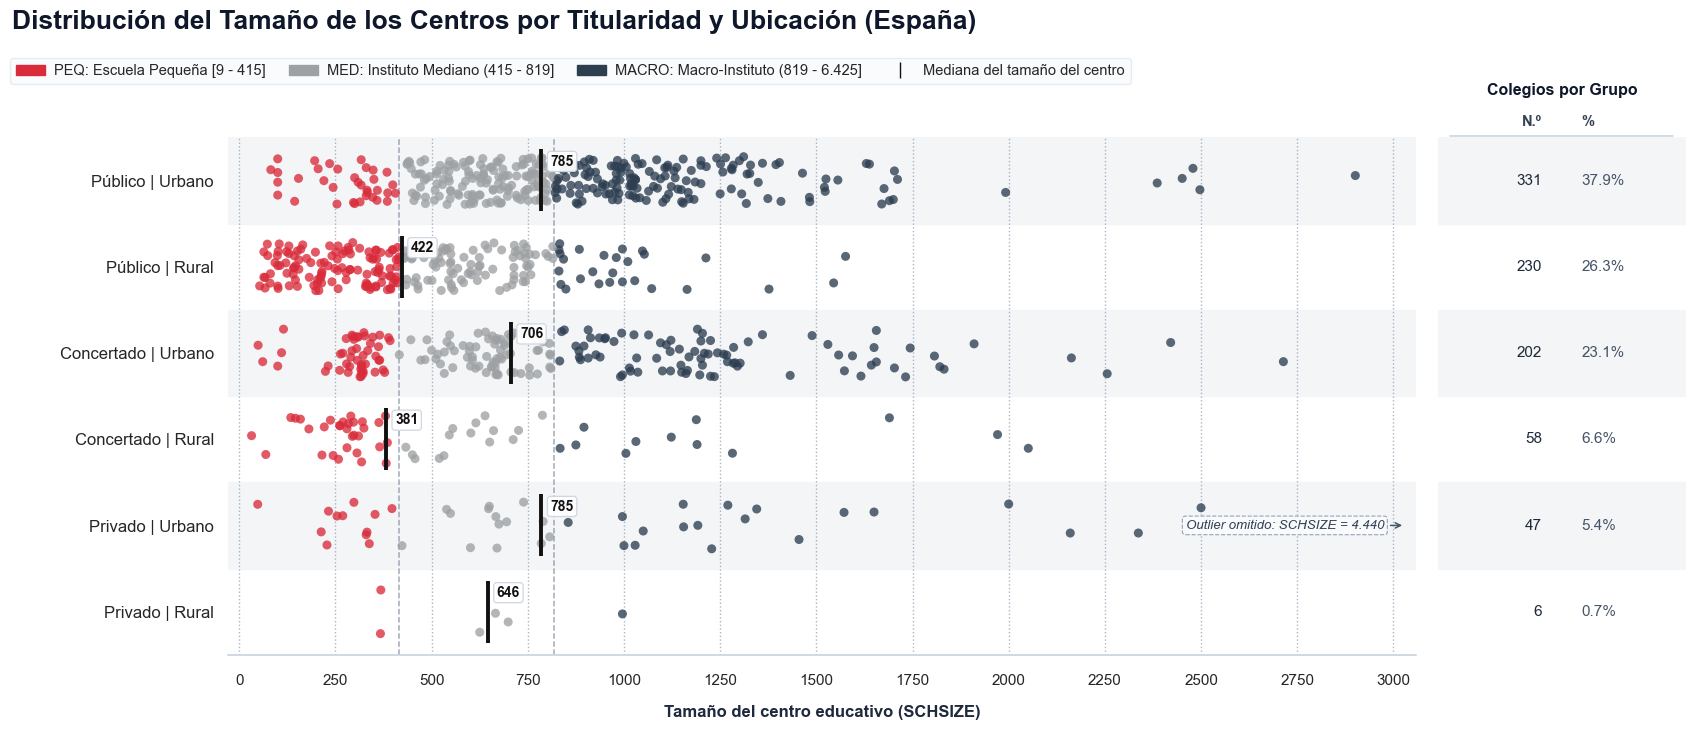

In [161]:
# Configuración visual en dos paneles (gráfico principal + tabla lateral independiente)
sns.set_theme(style="white")
fig, (ax, ax_tbl) = plt.subplots(
    1, 2,
    figsize=(18, 7.5),
    gridspec_kw={"width_ratios": [4.8, 1.0], "wspace": 0.03},
    sharey=True,
)
# Líneas verticales sutiles en los cortes de tamaño (415 y 819)
for corte in [415, 819]:
    ax.axvline(corte, color="#64748b", linestyle="--", linewidth=1.1, alpha=0.6, zorder=1)

# Stripplot donde cada fila es Titularidad | Ubicación y el color distingue PEQ, MED y MACRO
sns.stripplot(
    data=df_plot,
    x="SCHSIZE",
    y="GRUPO_INST",
    order=orden_grupos,
    hue="Tamanio_Categoria",
    palette={"PEQ": "#d92b3a", "MED": "#9ea1a3", "MACRO": "#2c3e50"},
    jitter=0.28,
    alpha=0.78,
    size=6.5,
    legend=False,
    ax=ax,
    zorder=2,
)

for i, grupo in enumerate(orden_grupos):
    if i % 2 == 0:
        ax.axhspan(i - 0.5, i + 0.5, color="#f3f5f7", zorder=0)
        ax_tbl.axhspan(i - 0.5, i + 0.5, color="#f3f5f7", zorder=0)

    mediana_val = medianas[grupo]
    if pd.notna(mediana_val):
        ax.vlines(
            x=mediana_val,
            ymin=i - 0.36,
            ymax=i + 0.36,
            colors="#111111",
            linewidth=2.8,
            zorder=4,
        )
        ax.text(
            mediana_val + 24,
            i - 0.22,
            f"{int(round(mediana_val))}",
            va="center",
            ha="left",
            fontsize=10,
            weight="bold",
            color="#111111",
            bbox=dict(
                boxstyle="round,pad=0.22",
                facecolor="white",
                edgecolor="#cbd5e1",
                alpha=0.94,
                linewidth=0.9,
            ),
            zorder=5,
        )

    # Datos de la tabla lateral (número de colegios y % sobre el total de colegios en España)
    n_total = int(stats.loc[grupo, "Total"])
    pct_total = stats.loc[grupo, "Porcentaje"]
    ax_tbl.text(0.42, i, f"{n_total:,}".replace(",", "."), va="center", ha="right", fontsize=11, weight="medium", color="#1e293b")
    ax_tbl.text(0.58, i, f"{pct_total:.1f}%", va="center", ha="left", fontsize=11, color="#475569")

# Ligera anotación para el outlier omitido en Privado | Urbano
for _, row_out in df_outliers.iterrows():
    idx_fila = orden_grupos.index(row_out["GRUPO_INST"])
    val_out = int(round(row_out["SCHSIZE"]))
    ax.annotate(
        f"Outlier omitido: SCHSIZE = {val_out:,}".replace(",", "."),
        xy=(UMBRAL_OUTLIER_VISUAL + 30, idx_fila),
        xytext=(UMBRAL_OUTLIER_VISUAL - 540, idx_fila),
        va="center",
        ha="left",
        fontsize=9.5,
        style="italic",
        color="#334155",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="#f8fafc",
            edgecolor="#94a3b8",
            linestyle="--",
            linewidth=0.8,
        ),
        arrowprops=dict(arrowstyle="->", color="#475569", lw=1.1),
        zorder=5,
    )

# Cabecera de la tabla lateral separada de la primera fila
ax_tbl.text(0.50, -1.05, "Colegios por Grupo", fontsize=11.5, weight="bold", ha="center", va="center", color="#0f172a", clip_on=False)
ax_tbl.text(0.42, -0.68, "N.º", fontsize=10.5, weight="bold", ha="right", va="center", color="#334155", clip_on=False)
ax_tbl.text(0.58, -0.68, "%", fontsize=10.5, weight="bold", ha="left", va="center", color="#334155", clip_on=False)
ax_tbl.plot([0.05, 0.95], [-0.51, -0.51], color="#cbd5e1", linewidth=1.2, clip_on=False)

# Ajuste de límites y ejes del gráfico principal
ax.set_xlim(-30, UMBRAL_OUTLIER_VISUAL + 60)
ax.set_xticks(range(0, UMBRAL_OUTLIER_VISUAL + 1, 250))
ax.set_ylim(len(orden_grupos) - 0.5, -0.5)

ax.xaxis.grid(True, linestyle=":", color="#94a3b8", alpha=0.8, zorder=1)
ax.yaxis.grid(False)
sns.despine(ax=ax, left=True, bottom=False, right=True, top=True)
ax.spines["bottom"].set_color("#cbd5e1")
ax.tick_params(axis="y", length=0, labelsize=12, pad=10)
ax.tick_params(axis="x", labelsize=11, pad=8)
ax.set_xlabel("Tamaño del centro educativo (SCHSIZE)", fontsize=12, weight="bold", labelpad=12, color="#1e293b")
ax.set_ylabel("")

# Limpieza del eje de la tabla lateral
ax_tbl.set_xlim(0, 1)
ax_tbl.axis("off")

# Título principal y leyenda unificada sin solapamientos
fig.suptitle(
    "Distribución del Tamaño de los Centros por Titularidad y Ubicación (España)",
    fontsize=19,
    weight="bold",
    x=0.04,
    y=0.97,
    ha="left",
    color="#0f172a",
)

peq_patch = mpatches.Patch(color="#d92b3a", label="PEQ: Escuela Pequeña [9 - 415]")
med_patch = mpatches.Patch(color="#9ea1a3", label="MED: Instituto Mediano (415 - 819]")
macro_patch = mpatches.Patch(color="#2c3e50", label="MACRO: Macro-Instituto (819 - 6.425]")
mediana_line = Line2D([0], [0], color="#111111", linewidth=2.8, marker="|", markersize=12, linestyle="None", label="Mediana del tamaño del centro")

fig.legend(
    handles=[peq_patch, med_patch, macro_patch, mediana_line],
    loc="upper left",
    bbox_to_anchor=(0.035, 0.915),
    frameon=True,
    facecolor="#f8fafc",
    edgecolor="#e2e8f0",
    ncol=4,
    fontsize=10.5,
    columnspacing=1.6,
    handletextpad=0.6,
)

fig.subplots_adjust(top=0.80, bottom=0.11, left=0.16, right=0.97)
plt.show()

## Visualización del número de colegios por estrato fijo entre ediciones (2012 - 2022)

A continuación se representa de forma comparativa el volumen de centros educativos clasificados dentro de cada uno de los 18 estratos fijos en las cuatro ediciones analizadas (`2012`, `2015`, `2018` y `2022`), permitiendo verificar la estabilidad y el tamaño muestral de colegios con el que se realiza la comparación en cada estrato.

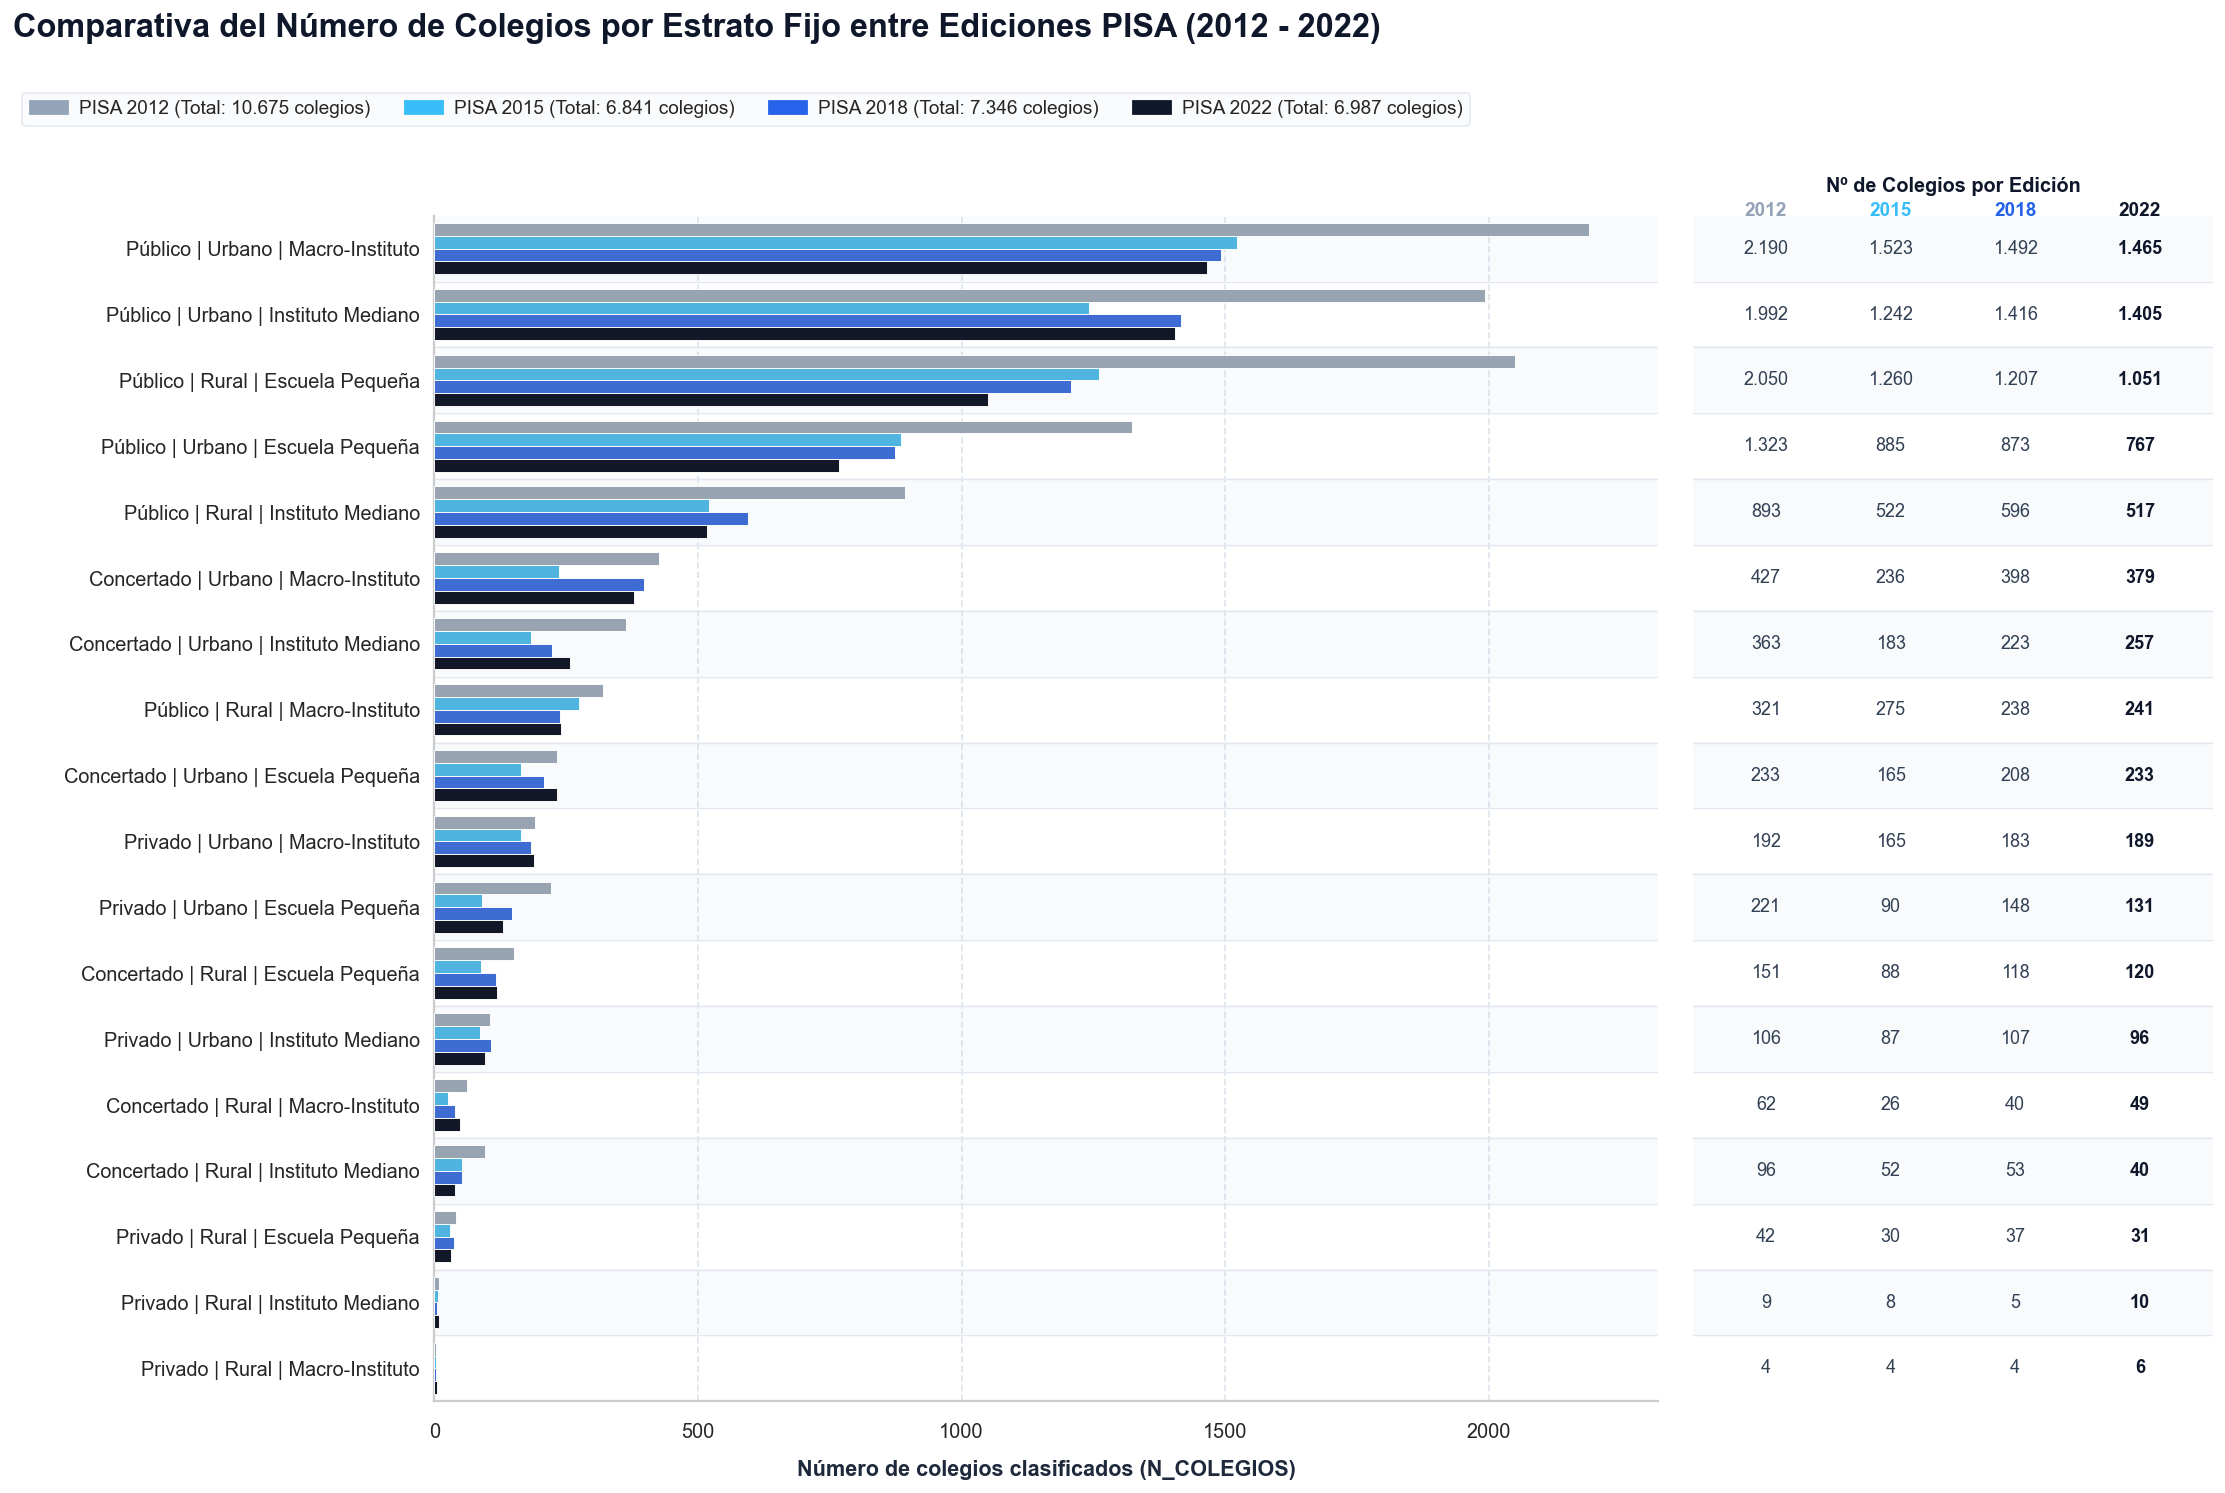

In [162]:
# Recopilación del conteo de colegios por estrato fijo en cada una de las cuatro ediciones
registros_comp = []
for edicion in [2012, 2015, 2018, 2022]:
    df_ed = estratos_colegios_por_edicion[edicion]
    conteo = (
        df_ed.groupby(["PERFIL_CODE", "PERFIL_DESC"])
        .size()
        .reset_index(name="N_COLEGIOS")
    )
    conteo["Edición"] = str(edicion)
    registros_comp.append(conteo)

df_comp_colegios = pd.concat(registros_comp, ignore_index=True)

# Tabla pivoteada (Estrato x Edición) ordenada de mayor a menor presencia en PISA 2022
tabla_colegios_ediciones = (
    df_comp_colegios.pivot(
        index=["PERFIL_CODE", "PERFIL_DESC"], columns="Edición", values="N_COLEGIOS"
    )[["2012", "2015", "2018", "2022"]]
    .fillna(0)
    .astype(int)
    .sort_values(by="2022", ascending=False)
)
tabla_colegios_ediciones.columns.name = None

orden_perfiles = tabla_colegios_ediciones.index.get_level_values("PERFIL_DESC").tolist()

# Configuración del lienzo en dos paneles sincronizados (barras horizontales + tabla comparativa)
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(18, 12), dpi=130)
gs = fig.add_gridspec(1, 2, width_ratios=[3.3, 1.4], wspace=0.04)
ax = fig.add_subplot(gs[0])
ax_tbl = fig.add_subplot(gs[1], sharey=ax)

# Paleta secuencial por edición para diferenciar la evolución temporal
paleta_ediciones = {
    "2012": "#94a3b8",
    "2015": "#38bdf8",
    "2018": "#2563eb",
    "2022": "#0f172a",
}

# Bandas horizontales alternas de fondo para guiar la lectura entre cada barra y sus cifras
for i in range(len(orden_perfiles)):
    bg_color = "#f8fafc" if i % 2 == 0 else "#ffffff"
    ax.axhspan(i - 0.5, i + 0.5, color=bg_color, zorder=0)
    ax_tbl.axhspan(i - 0.5, i + 0.5, color=bg_color, zorder=0)
    if i < len(orden_perfiles) - 1:
        ax.axhline(i + 0.5, color="#e2e8f0", linewidth=0.8, zorder=1)
        ax_tbl.axhline(i + 0.5, color="#e2e8f0", linewidth=0.8, zorder=1)

# Gráfico de barras agrupadas por edición para los 18 estratos fijos
sns.barplot(
    data=df_comp_colegios,
    x="N_COLEGIOS",
    y="PERFIL_DESC",
    order=orden_perfiles,
    hue="Edición",
    hue_order=["2012", "2015", "2018", "2022"],
    palette=paleta_ediciones,
    width=0.78,
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
    zorder=3,
)

if ax.get_legend() is not None:
    ax.get_legend().remove()

# Renderizado de la cabecera y las cifras exactas por edición en el panel derecho
x_cols = {"2012": 0.14, "2015": 0.38, "2018": 0.62, "2022": 0.86}
ax_tbl.text(
    0.50, -0.95, "Nº de Colegios por Edición",
    fontsize=11, weight="bold", color="#0f172a", ha="center", va="center"
)
for ed, x_pos in x_cols.items():
    ax_tbl.text(
        x_pos, -0.58, ed,
        fontsize=10.5, weight="bold", color=paleta_ediciones[ed], ha="center", va="center"
    )

for i, (code, desc) in enumerate(tabla_colegios_ediciones.index):
    fila = tabla_colegios_ediciones.loc[(code, desc)]
    for ed, x_pos in x_cols.items():
        val = int(fila[ed])
        ax_tbl.text(
            x_pos, i, f"{val:,}".replace(",", "."),
            fontsize=10,
            weight="bold" if ed == "2022" else "normal",
            color="#0f172a" if ed == "2022" else "#334155",
            ha="center", va="center"
        )

# Ajuste de límites, rejilla y etiquetas de los ejes
ax.set_ylim(len(orden_perfiles) - 0.5, -0.5)
max_x = int(df_comp_colegios["N_COLEGIOS"].max())
ax.set_xlim(0, max_x * 1.06)
ax.xaxis.grid(True, linestyle="--", alpha=0.6, color="#cbd5e1")
ax.yaxis.grid(False)
sns.despine(ax=ax, top=True, right=True, left=False, bottom=False)

ax.tick_params(axis="y", length=0, labelsize=11, pad=8)
ax.tick_params(axis="x", labelsize=11, pad=6)
ax.set_xlabel("Número de colegios clasificados (N_COLEGIOS)", fontsize=12, weight="bold", labelpad=10, color="#1e293b")
ax.set_ylabel("")

ax_tbl.set_xlim(0, 1)
ax_tbl.axis("off")

# Título superior y leyenda con el total muestral de colegios por edición
fig.suptitle(
    "Comparativa del Número de Colegios por Estrato Fijo entre Ediciones PISA (2012 - 2022)",
    fontsize=18,
    weight="bold",
    x=0.04,
    y=0.97,
    ha="left",
    color="#0f172a",
)

handles_leg = [
    mpatches.Patch(
        color=paleta_ediciones[ed],
        label=f"PISA {ed} (Total: {int(tabla_colegios_ediciones[ed].sum()):,} colegios)".replace(",", ".")
    )
    for ed in ["2012", "2015", "2018", "2022"]
]

fig.legend(
    handles=handles_leg,
    loc="upper left",
    bbox_to_anchor=(0.04, 0.925),
    frameon=True,
    facecolor="#f8fafc",
    edgecolor="#e2e8f0",
    ncol=4,
    fontsize=10.5,
    columnspacing=1.8,
    handletextpad=0.6,
)

fig.subplots_adjust(top=0.84, bottom=0.08, left=0.22, right=0.98)
plt.show()

# 7. Exportación de datos por edición

Guardamos la asociación entre el identificador único de cada estudiante (`['CNT', 'CNTSCHID', 'CNTSTUID']`) y su estrato fijo correspondiente (`PERFIL_CODE` y `PERFIL_DESC`) en 4 archivos `.parquet` independientes dentro de `../../data/intermediate/estratos_fijos/` para facilitar los cruces en análisis posteriores.

In [17]:
# Directorio de destino y columnas requeridas para el cruce alumno-estrato fijo
RUTA_EXPORT_ESTRATOS = Path("../../data/intermediate/estratos_fijos")
RUTA_EXPORT_ESTRATOS.mkdir(parents=True, exist_ok=True)

COLS_EXPORT_ESTRATO = ["CNT", "CNTSCHID", "CNTSTUID", "PERFIL_CODE", "PERFIL_DESC"]

# Fusión iterativa con los identificadores de alumnos y escritura de los 4 archivos .parquet
print("Exportación de estratos fijos por alumno completada:")
for edicion in [2022, 2018, 2015, 2012]:
    ruta_est = RUTA_DATOS_ANUALES / f"pisa{edicion}_estudiantes.parquet"
    df_ids_alumnos = pd.read_parquet(ruta_est, columns=["CNT", "CNTSCHID", "CNTSTUID"])
    df_colegios_ed = estratos_colegios_por_edicion[edicion][
        ["CNT", "CNTSCHID", "PERFIL_CODE", "PERFIL_DESC"]
    ]
    df_export = df_ids_alumnos.merge(
        df_colegios_ed,
        on=["CNT", "CNTSCHID"],
        how="inner",
        validate="many_to_one",
    )[COLS_EXPORT_ESTRATO]

    ruta_salida = RUTA_EXPORT_ESTRATOS / f"pisa{edicion}_estratos_fijos.parquet"
    df_export.to_parquet(ruta_salida, index=False)
    print(f"  - Edición {edicion}: {len(df_export):,} alumnos exportados -> {ruta_salida.as_posix()}")

Exportación de estratos fijos por alumno completada:
  - Edición 2022: 186,094 alumnos exportados -> ../../data/intermediate/estratos_fijos/pisa2022_estratos_fijos.parquet
  - Edición 2018: 189,532 alumnos exportados -> ../../data/intermediate/estratos_fijos/pisa2018_estratos_fijos.parquet
  - Edición 2015: 178,022 alumnos exportados -> ../../data/intermediate/estratos_fijos/pisa2015_estratos_fijos.parquet
  - Edición 2012: 265,820 alumnos exportados -> ../../data/intermediate/estratos_fijos/pisa2012_estratos_fijos.parquet


# 8. Limpieza de Memoria

In [163]:
# Liberación de estructuras auxiliares utilizadas durante el análisis y las visualizaciones
del df_temp_escs, escs_meso, df_sesgo, df_muestra_plot, df_colegios_raw